#### Implementation of SARIMAX model for JUMOSUC forcasting 

In [1]:
import os 
import sys
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from statsmodels.tsa.statespace.sarimax import SARIMAX
import joblib
import warnings
import seaborn as sns
warnings.filterwarnings("ignore")
from matplotlib import pyplot as plt
from sklearn.preprocessing import StandardScaler
import itertools


In [ ]:
# define SARIMAX : Seasonal AutoRegressive Integrated Moving Average with eXogenous factors

In [2]:
# load time series data
wkdir = r"C:/Users/agbob/OSUCLAB/ADD/FOSSE/osuc_digital_twin/"
data_dir = wkdir + "data/"

file_name = "cleaned_data.csv"

path = os.path.join(data_dir, file_name)

In [3]:
data = pd.read_csv(path, sep=",")

data["date"] = pd.to_datetime(data["date"], format="%Y-%m-%d %H:%M:%S")
data.set_index("date", inplace=True)

data.head()


,temperature_om,humidity_om,pressure_om,wind_speed_om,wind_direction_om,precipitation_om,soil_temperature_6cm_om,soil_temperature_18cm_om,soil_temperature_54cm_om,solarRadiation,...,temp_74cm_imputed,air_temperature_imputed,humi_6cm_imputed,humi_18cm_imputed,humi_54cm_imputed,humi_74cm_imputed,pH_6cm_imputed,pH_18cm_imputed,pH_54cm_imputed,pH_74cm_imputed
date,,,,,,,,,,,,,,,,,,,,,
2025-09-29 08:00:00,11.580501,86.0,1023.599976,5.506941,348.690094,0.0,10.980500,12.680500,14.9305,185.03,...,0,0,0,0,0,0,0,0,0,0
2025-09-29 09:00:00,13.980500,79.0,1023.700012,8.427383,19.983198,0.0,12.980500,12.680500,14.9305,245.69,...,0,0,0,0,0,0,0,0,0,0
2025-09-29 10:00:00,15.880500,75.0,1023.299988,10.086427,34.824570,0.0,15.130500,12.830501,14.8805,316.08,...,0,0,0,0,0,0,0,0,0,0
2025-09-29 11:00:00,17.280499,69.0,1023.000000,11.720751,42.510403,0.0,17.030499,13.180500,14.8805,318.51,...,0,0,0,0,0,0,0,0,0,0
2025-09-29 12:00:00,18.130499,61.0,1022.799988,12.096214,53.471054,0.0,18.030499,13.580501,14.8805,114.90,...,0,0,0,0,0,0,0,0,0,0


In [4]:
# normalize the data 
# scaler = StandardScaler()
# data = pd.DataFrame(scaler.fit_transform(data), columns=data.columns, index=data.index)

In [4]:
columns = [
    'temp_6cm', 'humi_6cm', 'pH_6cm',
    'temp_18cm', 'humi_18cm', 'pH_18cm',
    'temp_54cm', 'humi_54cm', 'pH_54cm',
    'temp_74cm', 'humi_74cm', 'pH_74cm'
]

exogenous_cols = [
    'temperature_om', 'humidity_om', 'pressure_om', 'wind_speed_om',
    'wind_direction_om', 'precipitation_om', 'soil_temperature_6cm_om',
    'soil_temperature_18cm_om', 'soil_temperature_54cm_om'
]

col_to_predict = 'temp_74cm'
t74_exo_cols = [
    'temp_6cm', 'temp_18cm', 'temp_54cm', 'humi_74cm',
]

Train, test = train_test_split(data, test_size=0.2, shuffle=False)

Y_train, Y_test, eXo_train, eXo_test = (
    Train[col_to_predict],
    test[col_to_predict],
    Train[t74_exo_cols],
    test[t74_exo_cols],
)


In [5]:
print(f"Train set from {Y_train.index.min()} to {Y_train.index.max()}")
print(f"Test set from {eXo_train.index.min()} to {eXo_train.index.max()}")

Train set from 2025-09-29 08:00:00 to 2025-10-22 05:00:00
Test set from 2025-09-29 08:00:00 to 2025-10-22 05:00:00


In [7]:
p = d = q = range(0, 2)
pdq = list(itertools.product(p, d, q))
seasonal_pdq = [(x[0], x[1], x[2], 12) for x in pdq]

best_aic = np.inf
best_param = None

for param in pdq:
    for param_seasonal in seasonal_pdq:
        try:
            mod = SARIMAX(
                Y_train,
                # exog=eXo_train,
                order=param,
                seasonal_order=param_seasonal,
                enforce_stationarity=False,
                enforce_invertibility=False,
            )

            results = mod.fit()

            if results.aic < best_aic:
                best_aic = results.aic
                best_param = (param, param_seasonal)

            print(
                f"SARIMAX{param}x{param_seasonal}6 - AIC:{results.aic}"
            )
        except:
            continue

SARIMAX(0, 0, 0)x(0, 0, 0, 12)6 - AIC:4535.517809516728
SARIMAX(0, 0, 0)x(0, 0, 1, 12)6 - AIC:4023.426687103665
SARIMAX(0, 0, 0)x(0, 1, 0, 12)6 - AIC:2917.189352351222
SARIMAX(0, 0, 0)x(0, 1, 1, 12)6 - AIC:2321.534455691535
SARIMAX(0, 0, 0)x(1, 0, 0, 12)6 - AIC:2913.0490130414296
SARIMAX(0, 0, 0)x(1, 0, 1, 12)6 - AIC:2343.538745208317
SARIMAX(0, 0, 0)x(1, 1, 0, 12)6 - AIC:1892.2374733233842
SARIMAX(0, 0, 0)x(1, 1, 1, 12)6 - AIC:1891.229472746108
SARIMAX(0, 0, 1)x(0, 0, 0, 12)6 - AIC:3779.5567827450805
SARIMAX(0, 0, 1)x(0, 0, 1, 12)6 - AIC:3285.958106909931
SARIMAX(0, 0, 1)x(0, 1, 0, 12)6 - AIC:2203.6113386044944
SARIMAX(0, 0, 1)x(0, 1, 1, 12)6 - AIC:1661.0288974532134
SARIMAX(0, 0, 1)x(1, 0, 0, 12)6 - AIC:2202.9493557178766
SARIMAX(0, 0, 1)x(1, 0, 1, 12)6 - AIC:1673.6528858899508
SARIMAX(0, 0, 1)x(1, 1, 0, 12)6 - AIC:1277.6733838849673
SARIMAX(0, 0, 1)x(1, 1, 1, 12)6 - AIC:1275.698701505125
SARIMAX(0, 1, 0)x(0, 0, 0, 12)6 - AIC:1129.2376867945093
SARIMAX(0, 1, 0)x(0, 0, 1, 12)6 - AIC:1

In [8]:
print(f"Best SARIMAX{best_param[0]}x{best_param[1]}24 - AIC:{best_aic}")

Best SARIMAX(1, 1, 1)x(1, 1, 1, 12)24 - AIC:375.46183443886065


In [6]:

model = SARIMAX(
    endog=Y_train,
    exog=eXo_train,
    order=(2, 1, 1),
    seasonal_order=(1, 1, 2, 12),
)
model_fit = model.fit()
print(model_fit.summary())


                                        SARIMAX Results                                        
Dep. Variable:                               temp_74cm   No. Observations:                  550
Model:             SARIMAX(2, 1, 1)x(1, 1, [1, 2], 12)   Log Likelihood                 210.738
Date:                                 Thu, 29 Jan 2026   AIC                           -399.476
Time:                                         08:19:57   BIC                           -352.331
Sample:                                     09-29-2025   HQIC                          -381.033
                                          - 10-22-2025                                         
Covariance Type:                                   opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
temp_6cm       0.5575      0.060      9.275      0.000       0.440       0

In [7]:
# test set prediction
Y_pred = model_fit.predict(
    start=Y_test.index.min(),
    end=Y_test.index.max(),
    exog=eXo_test
)
trn_rmse = np.sqrt(mean_squared_error(Y_train, model_fit.fittedvalues))
tst_rmse = np.sqrt(mean_squared_error(Y_test, Y_pred))
train_r2 = r2_score(Y_train, model_fit.fittedvalues)
test_r2 = r2_score(Y_test, Y_pred)
print(f"Train RMSE: {trn_rmse}, Train R2: {train_r2}")
print(f"Test RMSE: {tst_rmse}, Test R2: {test_r2}")

Train RMSE: 0.35319913546251863, Train R2: 0.976183965246189
Test RMSE: 2.8225854134138166, Test R2: -1.7466882222524074


In [8]:
rmse = np.sqrt(mean_squared_error(Y_test, Y_pred))
print(f"Test RMSE: {rmse}")

Test RMSE: 2.8225854134138166


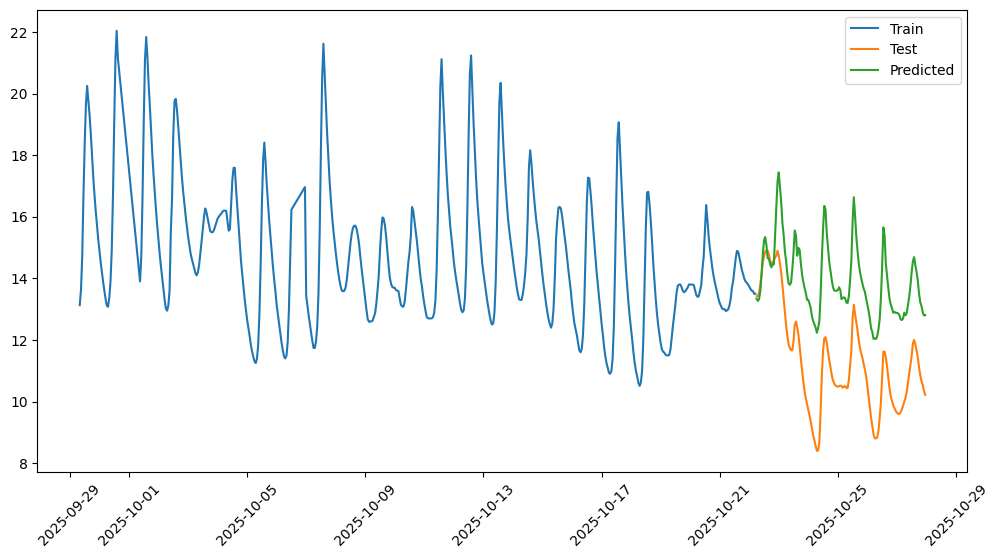

In [9]:
plt.figure(figsize=(12, 6))
plt.plot(Y_train.index, Y_train, label="Train")
plt.plot(Y_test.index, Y_test, label="Test")
plt.plot(Y_pred.index, Y_pred, label="Predicted")
plt.xticks(rotation=45)
plt.legend()
plt.show()

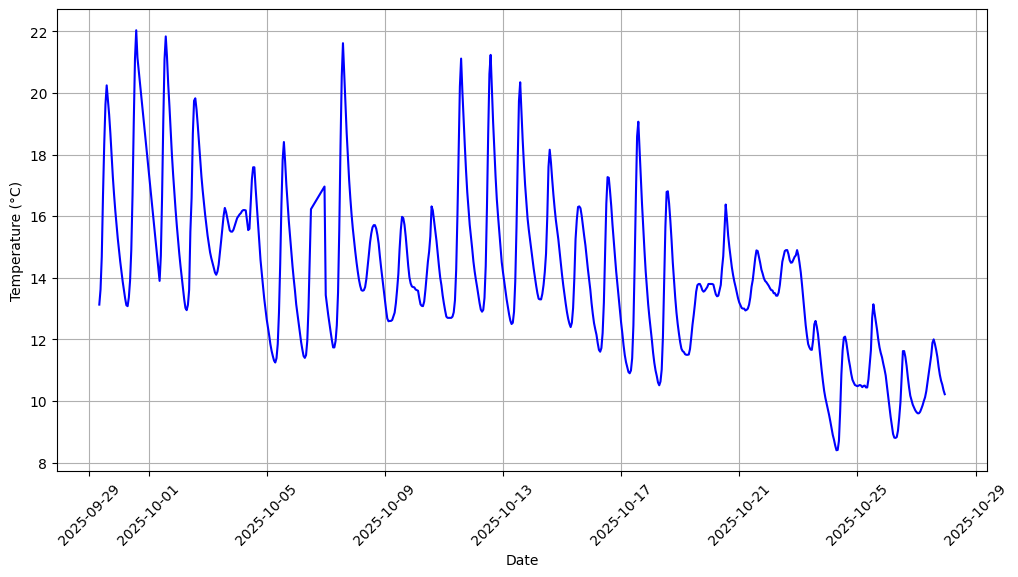

In [25]:
plt.figure(figsize=(12, 6))
plt.plot(data["temp_74cm"], label='Actual Temperature', color='blue')
# plt.plot(data["temp_18cm"], label='18cm Temperature', color='green', linestyle=':')
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.xticks(rotation=45)
plt.grid()
# plt.plot(data["temp_54cm"], label='54cm Temperature', color='orange', linestyle='-.')

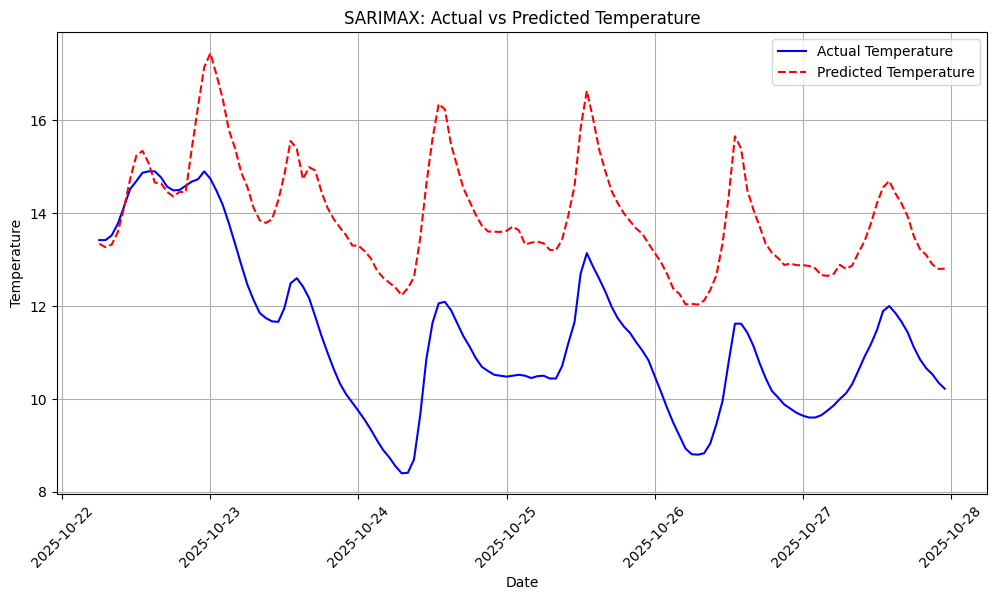

In [11]:
plt.figure(figsize=(12, 6))
plt.plot(Y_test.index, Y_test, label='Actual Temperature', color='blue')
plt.plot(Y_pred.index, Y_pred, label='Predicted Temperature', color='red', linestyle='--')
plt.xlabel('Date')
plt.ylabel('Temperature')
plt.xticks(rotation=45)
plt.grid()
plt.title('SARIMAX: Actual vs Predicted Temperature')
plt.legend()
plt.show()

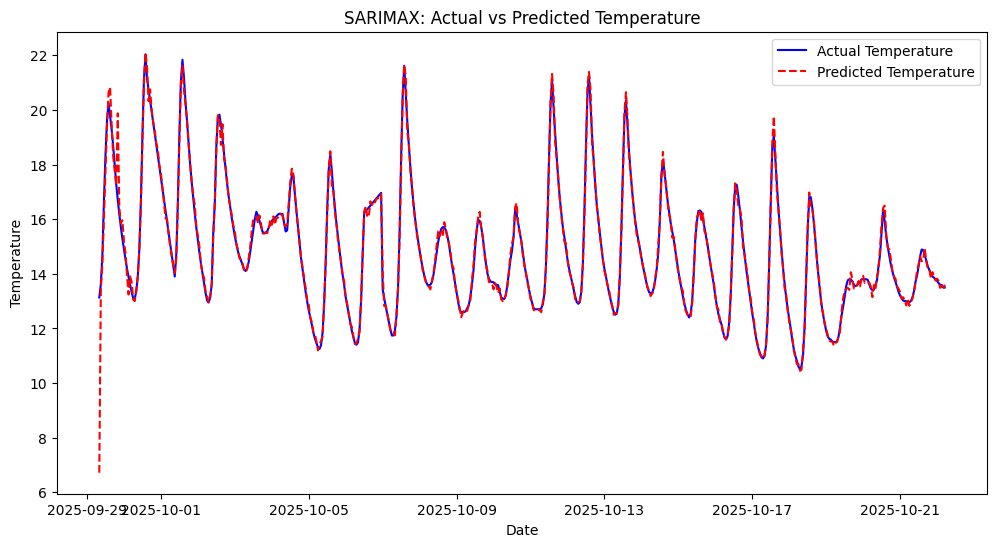

In [12]:
plt.figure(figsize=(12, 6))
plt.plot(Y_train.index, Y_train, label='Actual Temperature', color='blue')
plt.plot(Y_train.index, model_fit.fittedvalues, label='Predicted Temperature', color='red', linestyle='--' )
plt.xlabel('Date')
plt.ylabel('Temperature')
plt.title('SARIMAX: Actual vs Predicted Temperature')
plt.legend()
plt.show()

In [14]:
# explore lags on exo 

lag_results = pd.DataFrame(columns=['Lag', 'Test_RMSE', 'Test_R2'])

for lag in range(0, 12): 
    
    eXo_train_lagged = eXo_train.shift(lag).dropna()
    eXo_test_lagged = eXo_test.shift(lag).dropna()
    Y_train_lagged = Y_train[eXo_train_lagged.index]
    Y_test_lagged = Y_test[eXo_test_lagged.index]

    print(eXo_train_lagged.shape, Y_train_lagged.shape, eXo_test_lagged.shape, Y_test_lagged.shape)

    model_lagged = SARIMAX(
        endog=Y_train_lagged,
        exog=eXo_train_lagged,
        order=(2, 1, 1),
        seasonal_order=(1, 1, 2, 12),
    )
    model_fit_lagged = model_lagged.fit()

    # Y_pred_lagged = model_fit_lagged.predict(
    #     start=Y_test_lagged.index.min(),
    #     end=Y_test_lagged.index.max(),
    #     exog=eXo_test_lagged
    # )

    Y_pred_lagged = model_fit_lagged.forecast(steps=len(Y_test_lagged), exog=eXo_test_lagged)

    tst_rmse_lagged = np.sqrt(mean_squared_error(Y_test_lagged, Y_pred_lagged))
    test_r2_lagged = r2_score(Y_test_lagged, Y_pred_lagged)

    lag_results = pd.concat([lag_results, pd.DataFrame({'Lag': [lag], 'Test_RMSE': [tst_rmse_lagged], 'Test_R2': [test_r2_lagged]})], ignore_index=True)
    print(f"Lag: {lag} - Test RMSE: {tst_rmse_lagged}, Test R2: {test_r2_lagged}")

(550, 4) (550,) (138, 4) (138,)
Lag: 0 - Test RMSE: 2.8225854134138166, Test R2: -1.7466882222524074
(549, 4) (549,) (137, 4) (137,)
Lag: 1 - Test RMSE: 2.998927291974683, Test R2: -2.1125018651656493
(548, 4) (548,) (136, 4) (136,)
Lag: 2 - Test RMSE: 5.8324956927562095, Test R2: -10.820946534158459
(547, 4) (547,) (135, 4) (135,)
Lag: 3 - Test RMSE: 3.19548687491894, Test R2: -2.567660911289355
(546, 4) (546,) (134, 4) (134,)
Lag: 4 - Test RMSE: 2.7980730241673193, Test R2: -1.7598596239758009
(545, 4) (545,) (133, 4) (133,)
Lag: 5 - Test RMSE: 2.749096704598305, Test R2: -1.703661085956989
(544, 4) (544,) (132, 4) (132,)
Lag: 6 - Test RMSE: 3.0992860016192774, Test R2: -2.5130558705887847
(543, 4) (543,) (131, 4) (131,)
Lag: 7 - Test RMSE: 3.1048672452116826, Test R2: -2.6212262597309435
(542, 4) (542,) (130, 4) (130,)
Lag: 8 - Test RMSE: 3.4017323868989275, Test R2: -3.4896328512880324
(541, 4) (541,) (129, 4) (129,)
Lag: 9 - Test RMSE: 3.063388437464425, Test R2: -2.77176768938142

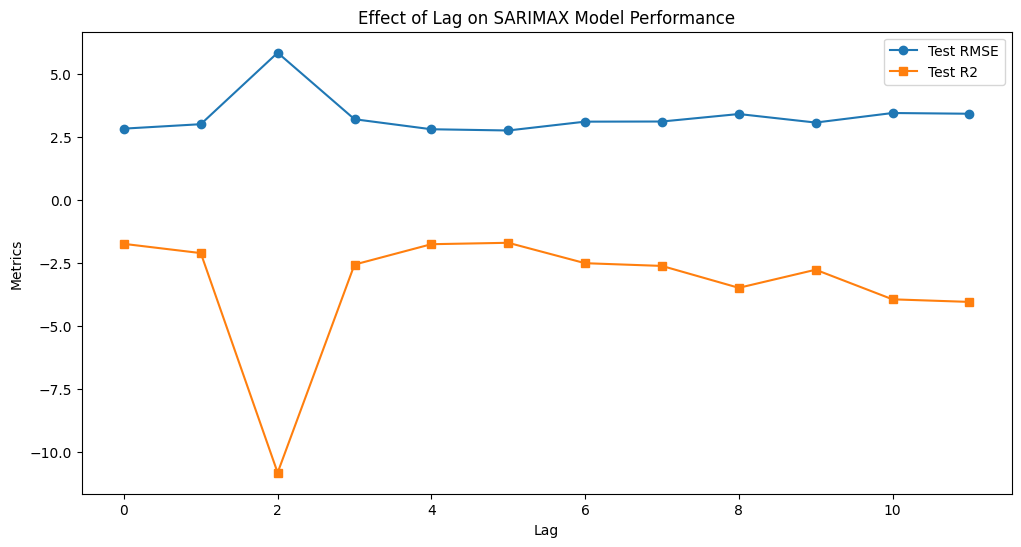

In [18]:
# plot lag results
plt.figure(figsize=(12, 6))
plt.plot(lag_results['Lag'], lag_results['Test_RMSE'], marker='o', label='Test RMSE')
plt.plot(lag_results['Lag'], lag_results['Test_R2'], marker='s', label='Test R2')
plt.xlabel('Lag')
plt.ylabel('Metrics')
plt.title('Effect of Lag on SARIMAX Model Performance')
plt.legend()
plt.show()

In [19]:
best_lag = lag_results.loc[lag_results['Test_RMSE'].idxmin(), 'Lag']
print(f"Best Lag based on Test RMSE: {best_lag}")

Best Lag based on Test RMSE: 5


In [21]:
lag_model = SARIMAX(
    endog=Y_train.shift(best_lag).dropna(),
    exog=eXo_train.shift(best_lag).dropna(),
    order=(2, 1, 1),
    seasonal_order=(1, 1, 2, 12),
)

lag_model_fit = lag_model.fit()
print(lag_model_fit.summary())

                                        SARIMAX Results                                        
Dep. Variable:                               temp_74cm   No. Observations:                  545
Model:             SARIMAX(2, 1, 1)x(1, 1, [1, 2], 12)   Log Likelihood                 206.647
Date:                                 Thu, 29 Jan 2026   AIC                           -391.294
Time:                                         09:03:28   BIC                           -344.251
Sample:                                     09-29-2025   HQIC                          -372.884
                                          - 10-22-2025                                         
Covariance Type:                                   opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
temp_6cm       0.5722      0.061      9.427      0.000       0.453       0

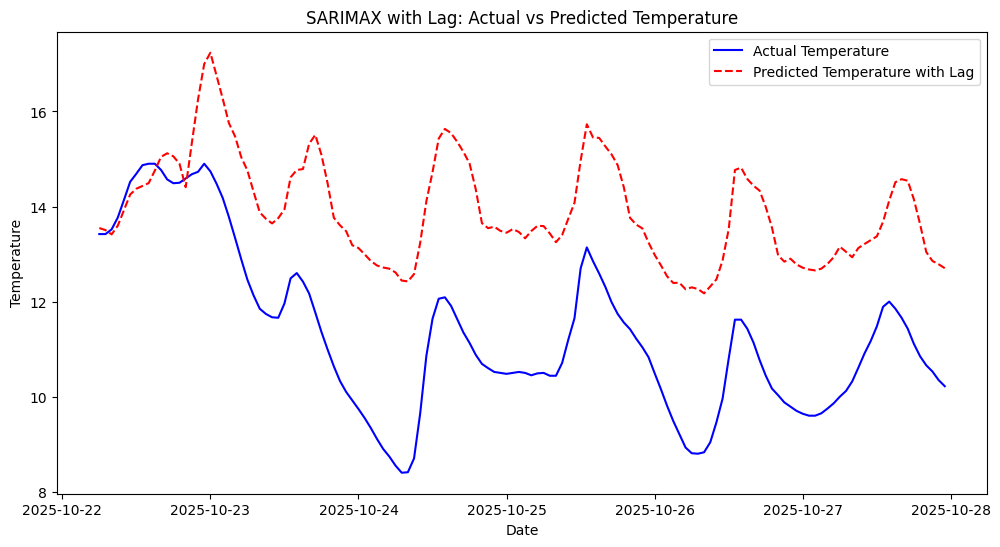

In [24]:
lag_eXo_test = eXo_test.shift(best_lag).dropna()
lag_pred = lag_model_fit.forecast(steps=len(Y_test), exog=eXo_test)
plt.figure(figsize=(12, 6))
plt.plot(Y_test.index, Y_test, label='Actual Temperature', color='blue')
plt.plot(lag_pred.index, lag_pred, label='Predicted Temperature with Lag', color='red', linestyle='--')
plt.xlabel('Date')
plt.ylabel('Temperature')
plt.title('SARIMAX with Lag: Actual vs Predicted Temperature')
plt.legend()
plt.show()

In [15]:
new_model = SARIMAX(
    endog=Y_train,
    # exog=eXo_train,
    order=(2, 1, 1),
    seasonal_order=(1, 1, 2, 12),
)
new_model_fit = new_model.fit()
print(new_model_fit.summary())

                                        SARIMAX Results                                        
Dep. Variable:                               temp_74cm   No. Observations:                  550
Model:             SARIMAX(2, 1, 1)x(1, 1, [1, 2], 12)   Log Likelihood                -120.307
Date:                                 Thu, 29 Jan 2026   AIC                            254.614
Time:                                         08:46:07   BIC                            284.616
Sample:                                     09-29-2025   HQIC                           266.351
                                          - 10-22-2025                                         
Covariance Type:                                   opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.5792      0.026     60.220      0.000       1.528       1

In [16]:
# test set prediction
new_Y_pred = new_model_fit.predict(
    start=Y_test.index.min(),
    end=Y_test.index.max(),
    # exog=eXo_test
)
trn_rmse = np.sqrt(mean_squared_error(Y_train, new_model_fit.fittedvalues))
tst_rmse = np.sqrt(mean_squared_error(Y_test, new_Y_pred))
train_r2 = r2_score(Y_train, new_model_fit.fittedvalues)
test_r2 = r2_score(Y_test, new_Y_pred)
print(f"Train RMSE: {trn_rmse}, Train R2: {train_r2}")
print(f"Test RMSE: {tst_rmse}, Test R2: {test_r2}")

Train RMSE: 0.7224801271803035, Train R2: 0.9003489215549728
Test RMSE: 2.8702793044845114, Test R2: -1.8402953239484559


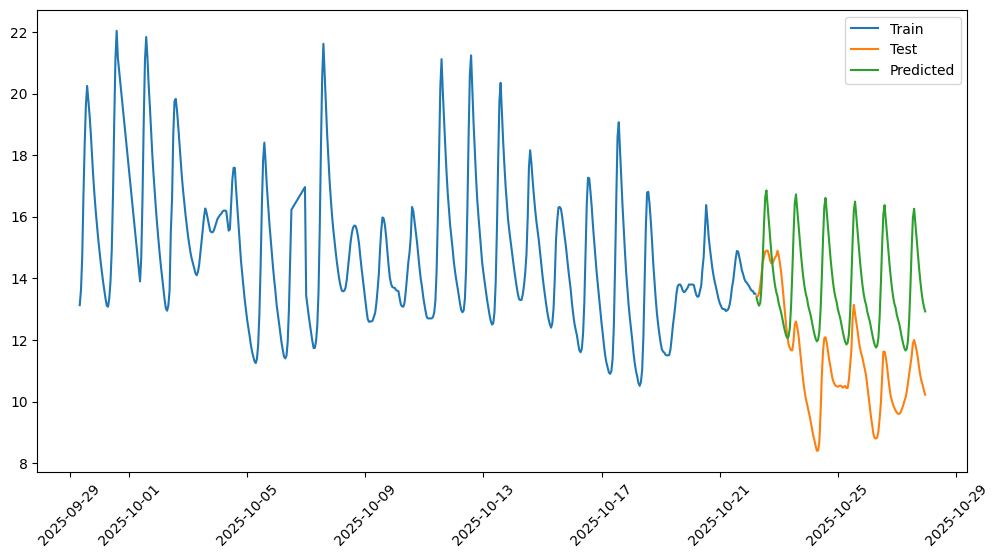

In [17]:
plt.figure(figsize=(12, 6))
plt.plot(Y_train.index, Y_train, label="Train")
plt.plot(Y_test.index, Y_test, label="Test")
plt.plot(new_Y_pred.index, new_Y_pred, label="Predicted")
plt.xticks(rotation=45)
plt.legend()
plt.show()